# Exercise 3 Implementing a Basic GAN

I trained a generative adversarial network (GAN) to create handwritten digits that look like MNIST images. The generator turns random numbers into an image. The discriminator looks at an image and estimates the chance that it came from MNIST.

## Data preparation

I used all 60,000 MNIST training images and kept the official test images separate for the visual comparison. I scaled the pixel values to the range from -1 to 1 to match the generator's tanh output. I kept the 28x28 pixel layout with one grayscale channel so the discriminator could look for local shapes and strokes. I shuffled the training images and used batches of 256 to keep the CPU run practical. I let TensorFlow prepare one batch ahead to reduce waiting between updates. I fixed the random seed so I could repeat the experiment more easily.

In [1]:
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(42)
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()
x_train = x_train.reshape(-1, 28, 28, 1).astype("float32") / 127.5 - 1.0

train_batches = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(len(x_train))
    .batch(256)
    .prefetch(1)
)

## Generator and discriminator

I gave the generator 64 random values drawn from a standard normal distribution so it could produce different digits and handwriting styles. I used a dense layer to create a small 7x7 grid and two transposed convolution layers to grow it to 14x14 and then 28x28. This lets the generator build up nearby pixels as strokes. I used batch normalization to keep the intermediate values on a steady scale, ReLU between the layers, and tanh to keep the final pixels between -1 and 1.

I used two small convolutional layers in the discriminator to look for local features such as strokes and curves. The stride of 2 makes each feature map smaller, which keeps the model compact. I used Leaky ReLU so negative inputs could still pass a small signal. A final dense layer with sigmoid gives a single real-image probability.

In [2]:
noise_size = 64

generator = tf.keras.Sequential([
    tf.keras.Input(shape=(noise_size,)),
    tf.keras.layers.Dense(7 * 7 * 32, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.Reshape((7, 7, 32)),
    tf.keras.layers.Conv2DTranspose(16, 4, strides=2, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh"),
])

discriminator = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(8, 3, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Conv2D(16, 3, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

## Training

For each batch, I first trained the discriminator to give a high score to real images and a low score to generated images. Then I drew fresh noise and trained the generator to make the updated discriminator give its images a high score. I used binary cross-entropy for both updates because the discriminator gives a probability. I used a separate Adam optimizer for each network and set the first momentum parameter to 0.5 so earlier gradients would have less influence. I gave the discriminator a smaller learning rate (0.0001). I used TensorFlow's to speed up the repeated batch updates.

I used the generator in training mode for both updates so its Batch Normalization layers used the statistics of the current batch each time. During the discriminator update, only the discriminator's trainable weights were adjusted. I used inference mode for the checkpoint images.

I trained for 100 epochs to see how the generated digits changed from early in training to the end of a longer run. I saved images after epochs 1, 10, 50, 80, and 100. I used the same eight noise vectors at each checkpoint and compared the generated images with real MNIST digits from the test set.

In [3]:
loss_fn = tf.keras.losses.BinaryCrossentropy()
d_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.5)
g_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

@tf.function
def train_batch(real_images):
    batch_size = tf.shape(real_images)[0]

    noise = tf.random.normal((batch_size, noise_size))
    fake_images = generator(noise, training=True)
    images = tf.concat([real_images, fake_images], axis=0)
    labels = tf.concat([tf.ones((batch_size, 1)), tf.zeros((batch_size, 1))], axis=0)
    with tf.GradientTape() as tape:
        d_loss = loss_fn(labels, discriminator(images, training=True))
    gradients = tape.gradient(d_loss, discriminator.trainable_variables)
    d_optimizer.apply_gradients(zip(gradients, discriminator.trainable_variables))

    noise = tf.random.normal((batch_size, noise_size))
    with tf.GradientTape() as tape:
        fake_images = generator(noise, training=True)
        scores = discriminator(fake_images)
        g_loss = loss_fn(tf.ones_like(scores), scores)
    gradients = tape.gradient(g_loss, generator.trainable_variables)
    g_optimizer.apply_gradients(zip(gradients, generator.trainable_variables))

    return tf.stack([d_loss, g_loss])

In [4]:
epochs = 100
fixed_noise = tf.random.normal((8, noise_size))
samples = {}
d_losses, g_losses = [], []

for epoch in range(1, epochs + 1):
    batch_losses = []
    for real_images in train_batches:
        batch_losses.append(train_batch(real_images))
    d_loss, g_loss = tf.reduce_mean(tf.stack(batch_losses), axis=0).numpy()
    d_losses.append(d_loss)
    g_losses.append(g_loss)

    if epoch in (1, 10, 50, 80, epochs):
        samples[epoch] = generator(fixed_noise, training=False).numpy()

    print(f"Epoch {epoch:2d}/{epochs} | Discriminator: {d_loss:.4f} | Generator: {g_loss:.4f}")

Epoch  1/100 | Discriminator: 0.6991 | Generator: 0.5183
Epoch  2/100 | Discriminator: 0.6935 | Generator: 0.5103
Epoch  3/100 | Discriminator: 0.6940 | Generator: 0.6488
Epoch  4/100 | Discriminator: 0.7007 | Generator: 0.6812
Epoch  5/100 | Discriminator: 0.6991 | Generator: 0.6904
Epoch  6/100 | Discriminator: 0.6972 | Generator: 0.6927
Epoch  7/100 | Discriminator: 0.6982 | Generator: 0.6925
Epoch  8/100 | Discriminator: 0.6967 | Generator: 0.6895
Epoch  9/100 | Discriminator: 0.6959 | Generator: 0.6945
Epoch 10/100 | Discriminator: 0.6950 | Generator: 0.6948
Epoch 11/100 | Discriminator: 0.6947 | Generator: 0.6928
Epoch 12/100 | Discriminator: 0.6937 | Generator: 0.6930
Epoch 13/100 | Discriminator: 0.6933 | Generator: 0.6934
Epoch 14/100 | Discriminator: 0.6918 | Generator: 0.6970
Epoch 15/100 | Discriminator: 0.6922 | Generator: 0.6947
Epoch 16/100 | Discriminator: 0.6911 | Generator: 0.6969
Epoch 17/100 | Discriminator: 0.6907 | Generator: 0.6945
Epoch 18/100 | Discriminator: 0

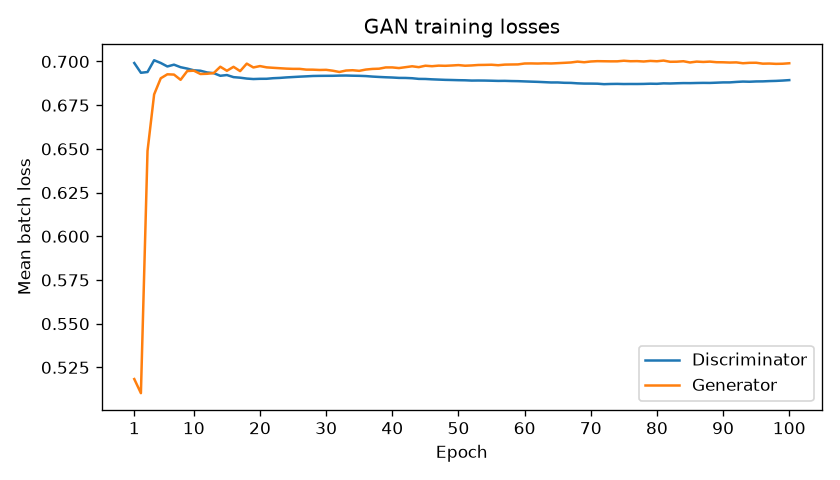

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), d_losses, label="Discriminator")
plt.plot(range(1, epochs + 1), g_losses, label="Generator")
plt.title("GAN training losses")
plt.xlabel("Epoch")
plt.ylabel("Mean batch loss")
plt.xticks([1, *range(10, epochs + 1, 10)])
plt.legend()
plt.tight_layout()
plt.show()

### Reading the loss curves

The generator and discriminator take turns learning from each other. When the discriminator gets better at spotting fake images, the generator can have a higher loss because its images are rejected more often. When the losses stay steady, the competition between the networks may be fairly balanced. The pictures can still change as both networks keep updating. I used the loss curves to follow the competition and the checkpoint images to judge the quality of the digits.

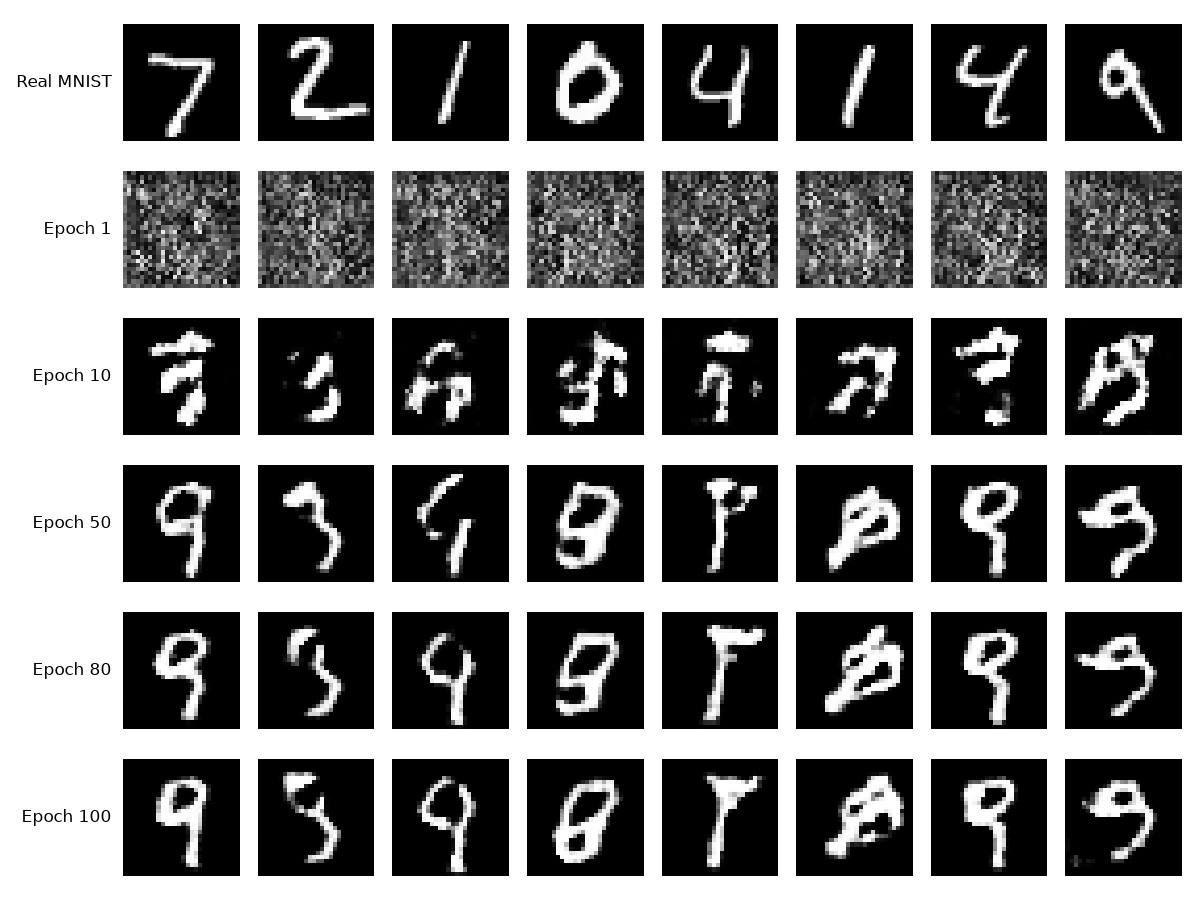

In [6]:
rows = [("Real MNIST", x_test[:8] / 127.5 - 1.0)]
rows += [(f"Epoch {epoch}", images) for epoch, images in samples.items()]

fig, axes = plt.subplots(len(rows), 8, figsize=(10, 1.25 * len(rows)))
for row, (label, images) in enumerate(rows):
    for ax, image in zip(axes[row], images):
        ax.imshow(image.reshape(28, 28), cmap="gray", vmin=-1, vmax=1)
        ax.set_axis_off()
    axes[row, 0].text(
        -0.1, 0.5, label, transform=axes[row, 0].transAxes, ha="right", va="center"
    )
fig.tight_layout()
plt.show()

## Results and discussion

At epoch 1, the generated images looked like gray noise. At epoch 10, I could see bright strokes against dark backgrounds, and several strokes were still disconnected. By epoch 50, the first and seventh samples looked like 9s. At epoch 80, a loop began to form in the third sample, and the fifth sample resembled a 7. At epoch 100, the samples are more look like real number similar to the real type of numbers.

I used the real MNIST images in the top row as a visual reference for the shapes and strokes of handwritten digits. Each generated image starts from noise, so it can resemble any digit. The real examples generally had more continuous strokes, and several generated digits still had gaps or extra marks.

After epoch 10, both losses stayed close to 0.69. The discriminator loss was 0.6893 and the generator loss was 0.6990 at epoch 100. The digit shapes became clearer between epochs 10 and 50 even as the losses changed very little.

In my first run with a generator made of dense layers, different noise inputs produced nearly identical images. This was a sign of mode collapse. The 100-epoch run produced different shapes, although several samples resembled 9s. The grid only shows eight examples, so it gives a limited view of how well the generator covers all ten digits.